# 二维 Poisson 参数族的解算子学习

主线三覆盖二维网格算子。区域为 $[-1,1]^2$，方程和边界为

$$-u_{xx}-u_{yy}=2\pi^2\sin(\pi x)\sin(\pi y),\qquad u|_{\partial\Omega}=0.$$

选择 **FNO × `physics_only`**：FNO 与规则二维网格自然匹配，训练目标只含 PDE/BC
残差，因此不需要观测 CSV。解析解 $\sin(\pi x)\sin(\pi y)$ 只在训练后画图比较，
不进入 loss。已提交的演示结果为 **10000** 步、训后相对 L2 约 **0.039**。
该数字由维护者接受为展示质量；自动阈值 0.03 仍记为 `passed: false`。
下面的固定随机种子、10 步 CPU **smoke** 只检查链路，不是该演示数字。

In [1]:
from pathlib import Path
import json
import math

import numpy as np
import torch

import openpinn as op

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file())
print("OpenPINN", op.__version__, "| CPU smoke | repo", ROOT.name)


OpenPINN 0.2.0 | CPU smoke | repo OpenPINN-upstream


## 定义二维 PDE 与边界

In [2]:
domain = op.Polygon([(-1, -1), (1, -1), (1, 1), (-1, 1)])

def poisson_residual(coordinates, prediction):
    forcing = 2.0 * math.pi**2 * torch.sin(math.pi * coordinates[:, 0:1]) * torch.sin(math.pi * coordinates[:, 1:2])
    return -op.hessian(prediction, coordinates, i=0, j=0) - op.hessian(prediction, coordinates, i=1, j=1) - forcing

problem = op.PDEProblem(domain, poisson_residual, [op.DirichletBC(0.0)], name="poisson_2d")
config = op.build_operator_config(
    "fno", training_mode="physics_only", n_dims=2,
    in_channels=1, out_channels=1, width=6, n_layers=1,
    n_modes=3, project_width=8, grid_size=10, batch_size=1,
    n_harmonics=1, derivative="finite_difference", steps=10,
    seed=0, lr=1e-2, physics_weight=1.0,
)
print(problem.name, "|", config["operator"], "×", config["training_mode"], "| no observation CSV")

poisson_2d | fno × physics_only | no observation CSV


## physics-only 训练

In [3]:
result = op.train_operator_problem(
    config, problem, device="cpu",
    input_function=lambda points: 2.0 * math.pi**2 * torch.sin(math.pi * points[:, 0:1]) * torch.sin(math.pi * points[:, 1:2]),
)
print(json.dumps({
    "initial_physics_loss": result.metrics["initial_physics_loss"],
    "final_physics_loss": result.metrics["final_physics_loss"],
}, indent=2))

{
  "initial_physics_loss": 151.33570861816406,
  "final_physics_loss": 17.83686065673828
}


## Smoke 指标

固定种子 10 步 CPU **smoke** 只检查调用链路，不是演示数字。物理损失已打印在上面的训练输出中；下面只打印训后参考相对 L2，不再绘制 smoke 损失曲线或场对比。演示图见下一节，文件在 `examples/tutorials/artifacts/m19/fno_physics_only/`。


In [5]:
axis = torch.linspace(-1.0, 1.0, config["grid_size"])
xx, yy = torch.meshgrid(axis, axis, indexing="ij")
coordinates = torch.stack((xx.reshape(-1), yy.reshape(-1)), dim=1)
with torch.no_grad():
    prediction = result.evaluator(coordinates).cpu().numpy()[:, 0]
reference = (torch.sin(math.pi * coordinates[:, 0]) * torch.sin(math.pi * coordinates[:, 1])).numpy()
relative_l2 = float(np.linalg.norm(prediction - reference) / np.linalg.norm(reference))
print("post-train reference relative L2:", relative_l2, "| reference never entered physics_only loss")

post-train reference relative L2: 0.44945642352104187 | reference never entered physics_only loss


## 已提交的演示结果

下图来自维护者演示训练，文件在 `examples/tutorials/artifacts/m19/fno_physics_only/`。训后相对 L2 约 **0.039**（10000 步）。自动阈值 0.03 仍为 `passed: false`，维护者接受该展示质量。上面的 CPU **smoke** 只检查调用链路。


demo stop_steps=10000 post_train_relative_l2=0.038914 passed=False | target 0.03 (user-accepted showcase)


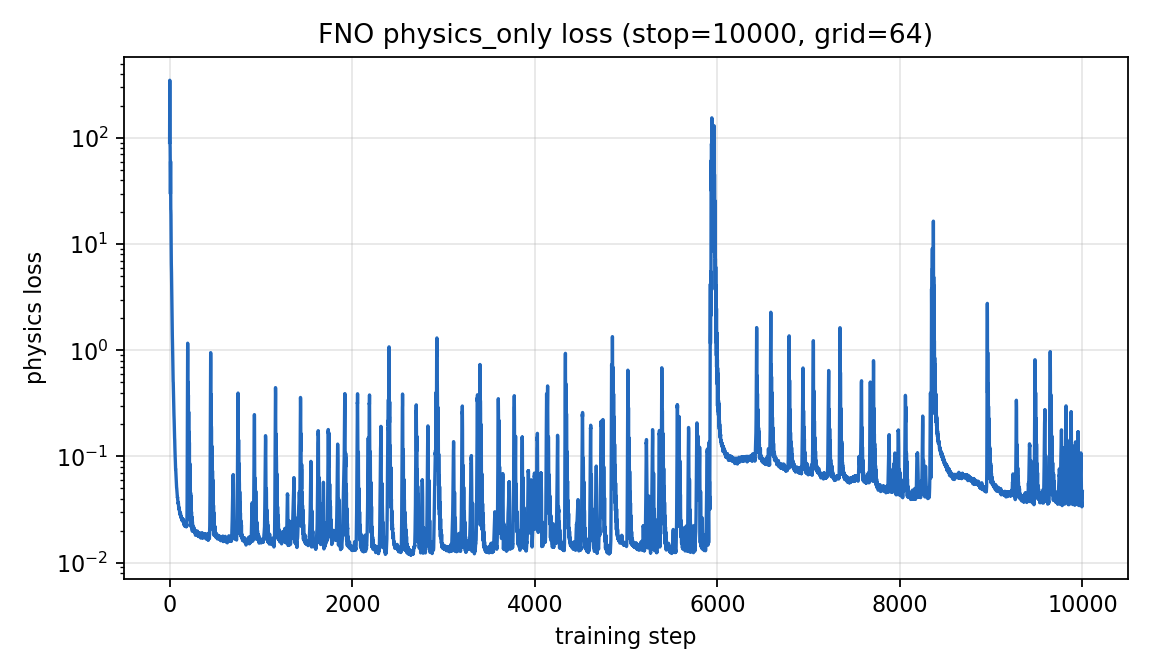

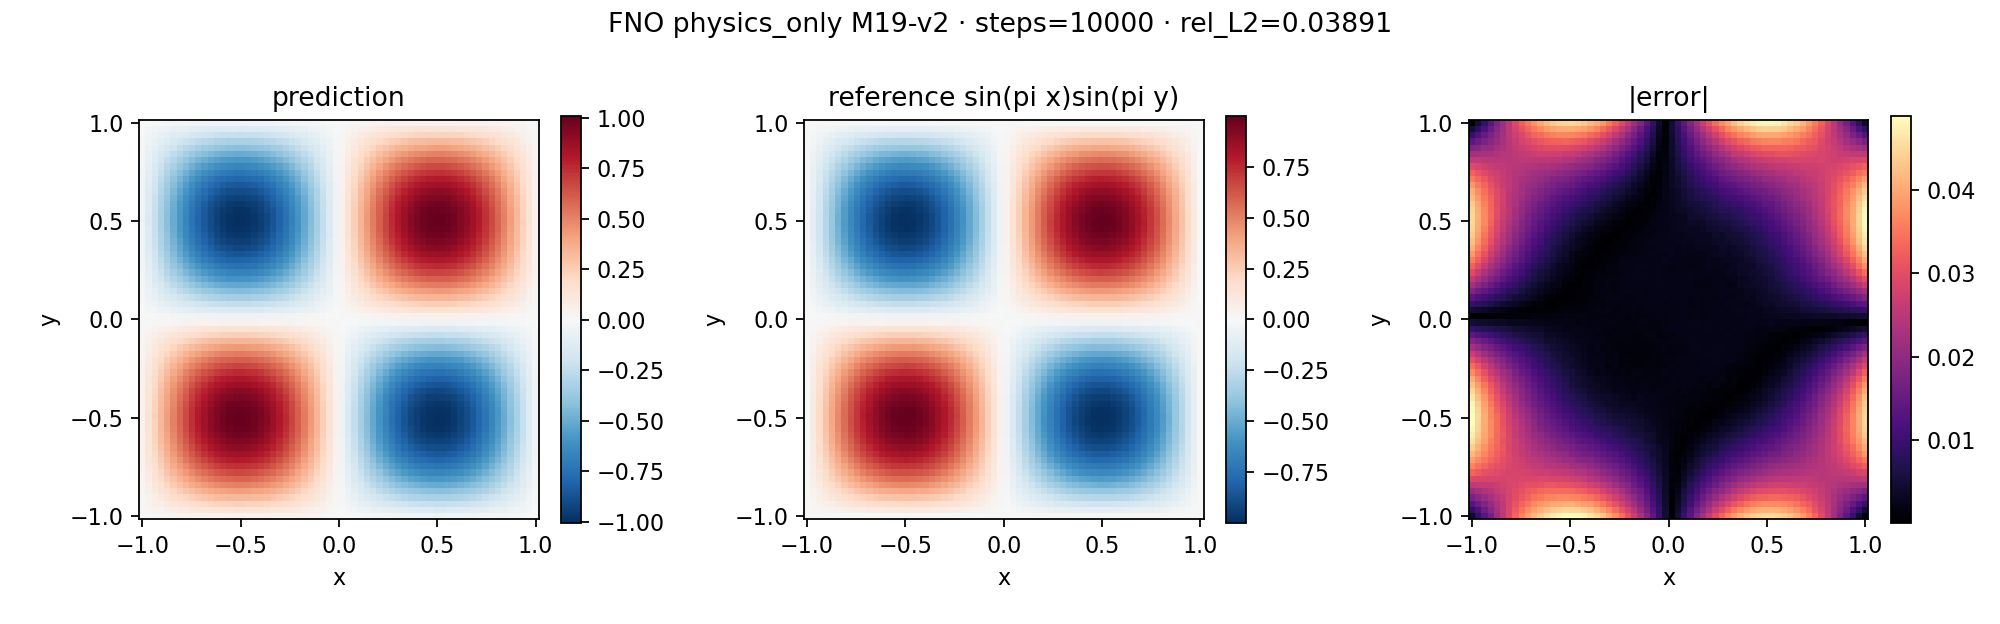

In [1]:
from pathlib import Path
import json
from IPython.display import Image, display

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file())
art = ROOT / "examples/tutorials/artifacts/m19/fno_physics_only"
metrics = json.loads((art / "metrics.json").read_text(encoding="utf-8"))
print(
    f"demo stop_steps={metrics['stop_steps']} "
    f"post_train_relative_l2={metrics['post_train_relative_l2']:.6f} "
    f"passed={metrics['passed']} | target {metrics['target_post_train_relative_l2']} "
    "(user-accepted showcase)"
)
display(Image(filename=str(art / "loss.png")))
display(Image(filename=str(art / "solution_vs_reference.png")))
